In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

def softplus(z, beta=5.0):
    return np.logaddexp(0.0, beta * z) / beta

def make_ground_truth_params(
    K=4,        # latent dimensionality
    N=128,       # number of channels
    spectral_radius=0.9,  # eig_A < 1 for stability
    sigma2_Q=0.05,
    sigma2_C=1.0,
    w=3.0,       # spatial spread radius
    b_input=0.8,       # perturbation threshold
    seed=0,
):
    """
    Construct ground-truth PLDS parameters.
    """
    rng = np.random.default_rng(seed)

    # Skew symmetric for rotational dynamics
    S_raw = rng.standard_normal((K, K))
    S = (S_raw - S_raw.T) / 2  # make skew-symmetric
    # In a skew-symmetric matrix its eigenvalues are purely imaginary (jθ), so rescale theta to be <= pi/6
    eigvals_S = np.linalg.eigvals(S)
    max_theta = np.max(np.abs(eigvals_S.imag))
    max_angle = np.pi / 6
    if max_theta > 0:
        S = S * (max_angle / max_theta)

    # Diagonals of S is zero, treat as continuous version and get discrete A
    # Or you can think of it as expm(S) is the matrix analogue of e^(jθ) where the rotation lies on the unit circle
    A = spectral_radius * expm(S)

    # Stim-to-latent mapping
    B = rng.standard_normal((K, N)) * 5 #/ np.sqrt(N) 

    # Perturbation threshold
    b = b_input

    # Loading matrix
    C = rng.standard_normal((N, K)) * np.sqrt(sigma2_C / K)

    # Per-channel mean log-firing rate
    d = rng.normal(loc=1.0, scale=1, size=N)

    # Latent process noise covariance (diagonal)
    Q = sigma2_Q * np.eye(K)

    # Initial state
    mu0 = np.zeros(K)
    Sigma0 = np.eye(K)

    # Toeplitz matrix
    idx = np.arange(N)
    diff = idx[:, None] - idx[None, :] # This gives the distance between channels
    V_unnorm = np.exp(-(diff ** 2) / (2 * w ** 2))
    Z = V_unnorm.sum(axis=1, keepdims=True)
    V = V_unnorm / Z

    return dict(A=A, B=B, b=b, C=C, d=d, Q=Q, mu0=mu0, Sigma0=Sigma0, V=V)

In [3]:
def simulate_trial(params, T, stim_channels, t_stim, rng, softplus_beta = 5.0):
    """
    Simulate one trial of the PLDS.

    Parameters
    ----------
    params : dict from make_ground_truth_params
    T : number of within-trial timesteps
    stim_channels : array of channel indices to stimulate (one-hot)
    t_stim : int, timestep at which stimulation is delivered
    rng : np.random.Generator

    Returns
    -------
    x : (T, K) latent trajectory
    y : (T, N) spike counts
    s : (T, N) stim indicator over time (nonzero only at t_stim)
    """
    # Unpack
    A, B, b, C, d, Q, mu0, Sigma0, V = (
        params["A"], params["B"], params["b"], params["C"], params["d"],
        params["Q"], params["mu0"], params["Sigma0"], params["V"],
    )
    
    # Dimensions
    K = A.shape[0]
    N = C.shape[0]

    # Preallocate
    s = np.zeros((T, N))
    s[t_stim, stim_channels] = 1.0
    x = np.zeros((T, K))
    y = np.zeros((T, N), dtype=int)

    x_prev = rng.multivariate_normal(mu0, Sigma0)
    L_Q = np.linalg.cholesky(Q) # If Q is diagonal, its L_Q 

    for t in range(T):
        stim_input = B @ softplus(V @ s[t] + b, softplus_beta) if t == t_stim else np.zeros(K)
        
        eps = L_Q @ rng.standard_normal(K) # Sample noise using Cholesky factor
        x_t = A @ x_prev + stim_input + eps
        
        # Measurement
        rate = softplus(C @ x_t + d, softplus_beta)
        y_t = rng.poisson(rate) # Ogada sampling process

        # Save results and index
        x[t] = x_t
        y[t] = y_t
        x_prev = x_t
    return x, y, s

Ground-truth parameters:
  A: (4, 4)
  B: (4, 128)
  b: float
  C: (128, 4)
  d: (128,)
  Q: (4, 4)
  mu0: (4,)
  Sigma0: (4, 4)
  V: (128, 128)


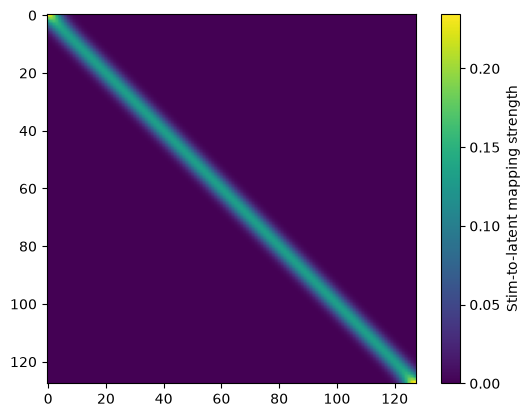

In [4]:
K = 4
N = 128

rng = np.random.default_rng(1)
params = make_ground_truth_params(K=K, N=N, spectral_radius = 0.9, 
                                  sigma2_Q = 0.01, sigma2_C = 0.1, w = 3.0, 
                                  b_input = -0.5, seed=0)

print("Ground-truth parameters:")
for key, value in params.items():
    print(f"  {key}: {value.shape if hasattr(value, 'shape') else type(value).__name__}")
    
plt.imshow(params['V'], cmap='viridis')
plt.colorbar(label='Stim-to-latent mapping strength')

In [5]:
# Sim params
T = 60          # within-trial timesteps
t_stim = 25      # stim delivered at this timestep
pad_T = 40
n_stim_ch = 8    # number of channels stimulated per trial
n_trials = 50
softplus_beta = 5

T_total = T + pad_T
t_stim_padded = t_stim + pad_T

# Preallocate at the padded length
X = np.zeros((n_trials, T_total, K))
Y = np.zeros((n_trials, T_total, N), dtype=int)
S = np.zeros((n_trials, T_total, N))

# Simulate with burn-in, then trim
for i in range(n_trials):
    start_idx = rng.integers(0, N - n_stim_ch + 1)
    stim_channels = np.arange(start_idx, start_idx + n_stim_ch)
    x, y, s = simulate_trial(params, T_total, stim_channels, t_stim_padded, rng)
    X[i], Y[i], S[i] = x, y, s

# Trim off the burn-in period
X = X[:, pad_T:, :]
Y = Y[:, pad_T:, :]
S = S[:, pad_T:, :]

X_spread = np.zeros((n_trials, T_total, K))
Y_spread = np.zeros((n_trials, T_total, N), dtype=int)
S_spread = np.zeros((n_trials, T_total, N))

for i in range(n_trials):
    start_idx = rng.integers(0, N - n_stim_ch + 1)
    stim_channels_spread = rng.choice(N, size=n_stim_ch, replace=False)
    x_spread, y_spread, s_spread = simulate_trial(params, T_total, stim_channels_spread, t_stim_padded, rng)
    X_spread[i], Y_spread[i], S_spread[i] = x_spread, y_spread, s_spread

X_spread = X_spread[:, pad_T:, :]
Y_spread = Y_spread[:, pad_T:, :]
S_spread = S_spread[:, pad_T:, :]
    
    
print("X (latents):", X.shape) # n_trials x time x latent_dim
print("Y (spikes):", Y.shape) # n_trials x time x obs_dim
print("S (stim):", S.shape) # n_trials x time x obs_dim

X (latents): (50, 60, 4)
Y (spikes): (50, 60, 128)
S (stim): (50, 60, 128)


In [6]:
stim_channels, params['b']

(array([82, 83, 84, 85, 86, 87, 88, 89]), -0.5)

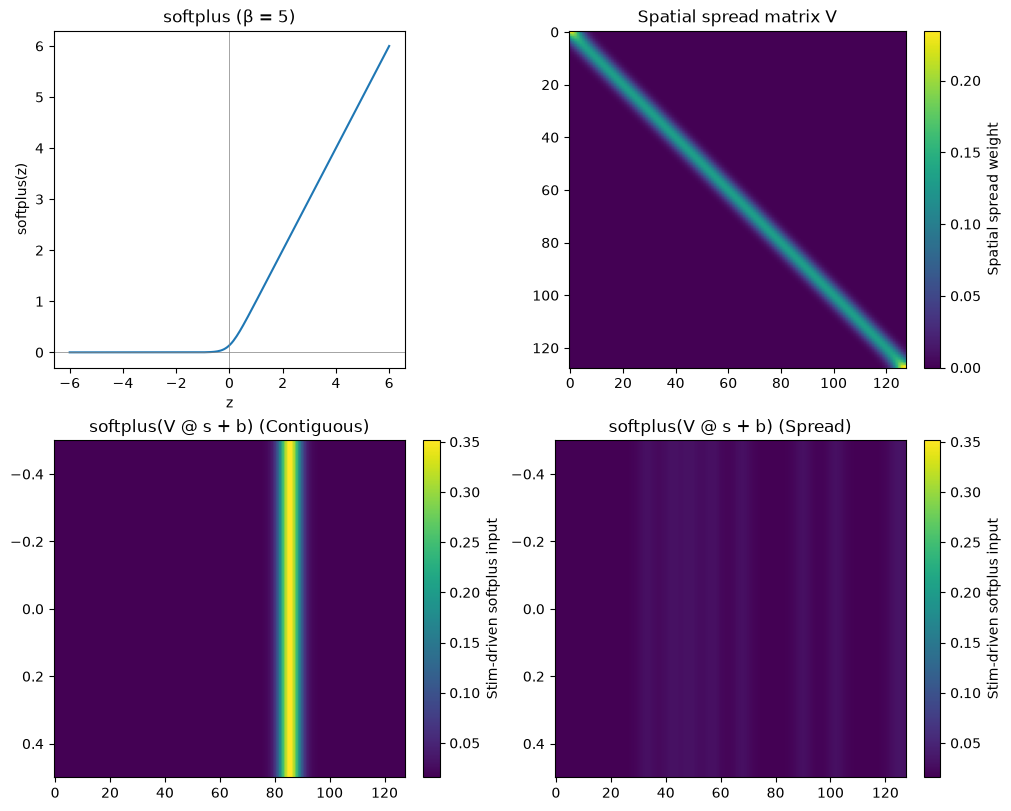

In [7]:
s_temp = np.zeros(N)
s_temp_spread = np.zeros(N)
s_temp[stim_channels] = 1.0
s_temp_spread[stim_channels_spread] = 1.0

fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)

# Top left: softplus
z_range = np.linspace(-6, 6, 200)
axes[0, 0].plot(z_range, softplus(z_range))
axes[0, 0].axhline(0, color="grey", linewidth=0.5)
axes[0, 0].axvline(0, color="grey", linewidth=0.5)
axes[0, 0].set_title(f"softplus (β = {softplus_beta})")
axes[0, 0].set_xlabel("z")
axes[0, 0].set_ylabel("softplus(z)")

# Top right: V matrix
im0 = axes[0, 1].imshow(params['V'], cmap='viridis')
axes[0, 1].set_title("Spatial spread matrix V")
fig.colorbar(im0, ax=axes[0, 1], label='Spatial spread weight')

# Bottom left
stim_effect = softplus(params['V'] @ s_temp + params['b'])
stim_effect_spread = softplus(params['V'] @ s_temp_spread + params['b'])

vmin, vmax = stim_effect.min(), stim_effect.max()  # Get colorbar from first

im1 = axes[1, 0].imshow(stim_effect[None, :], cmap='viridis', aspect='auto', vmin=vmin, vmax=vmax)
axes[1, 0].set_title(f"softplus(V @ s + b) (Contiguous)")
fig.colorbar(im1, ax=axes[1, 0], label='Stim-driven softplus input')

# Bottomr right is spread
im2 = axes[1, 1].imshow(stim_effect_spread[None, :], cmap='viridis', aspect='auto', vmin=vmin, vmax=vmax)
axes[1, 1].set_title(f"softplus(V @ s + b) (Spread)")
fig.colorbar(im2, ax=axes[1, 1], label='Stim-driven softplus input')

plt.show()

In [8]:
stim_channels, stim_channels_spread, params['b']

(array([82, 83, 84, 85, 86, 87, 88, 89]),
 array([ 33,  57, 124,  42,  49, 102,  90,  68]),
 -0.5)

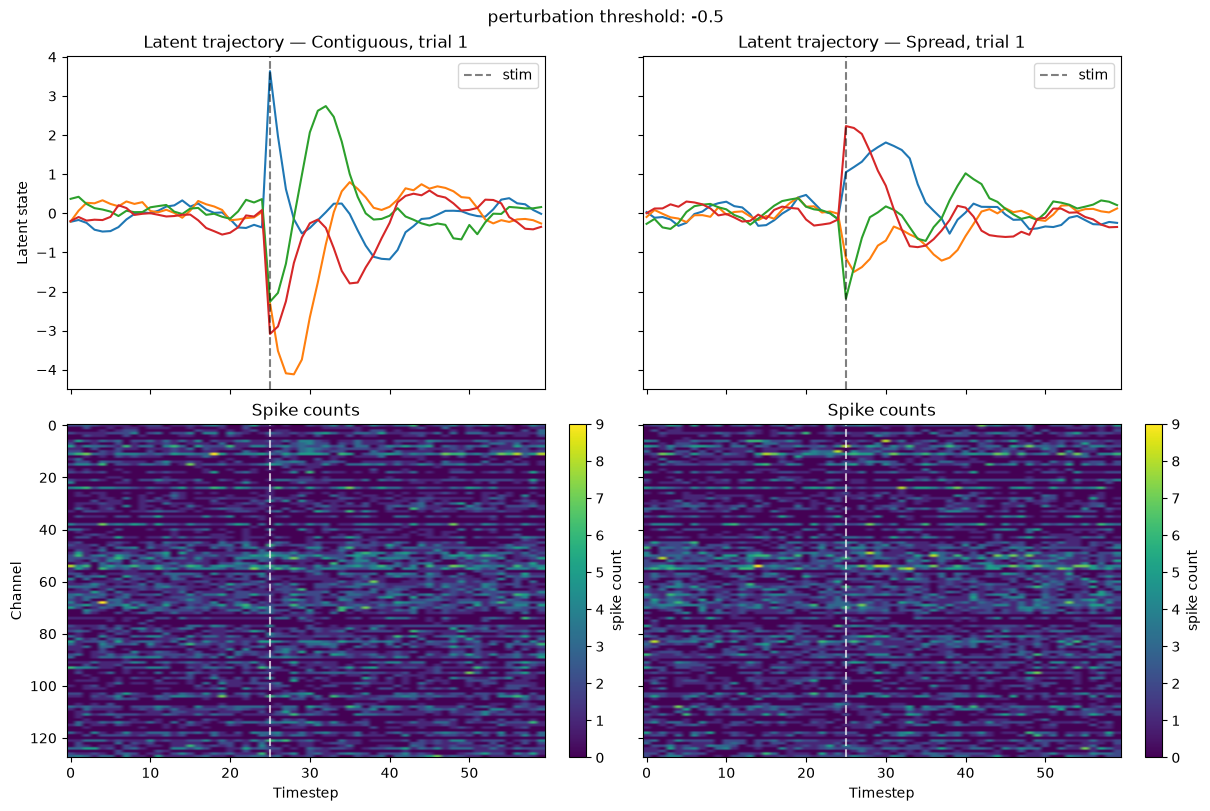

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True, sharex=True, sharey='row')

trial_idx = 0

# Left column: Contiguous
axes[0, 0].plot(X[trial_idx])
axes[0, 0].axvline(t_stim, color="k", linestyle="--", alpha=0.5, label="stim")
axes[0, 0].set_title(f"Latent trajectory — Contiguous, trial {trial_idx+1}")
axes[0, 0].set_ylabel("Latent state")
axes[0, 0].legend()

im1 = axes[1, 0].imshow(Y[trial_idx].T, aspect="auto", cmap="viridis")
axes[1, 0].axvline(t_stim, color="w", linestyle="--", alpha=0.7)
axes[1, 0].set_title("Spike counts")
axes[1, 0].set_xlabel("Timestep")
axes[1, 0].set_ylabel("Channel")
fig.colorbar(im1, ax=axes[1, 0], label="spike count")

# Right: Spread
axes[0, 1].plot(X_spread[trial_idx])
axes[0, 1].axvline(t_stim, color="k", linestyle="--", alpha=0.5, label="stim")
axes[0, 1].set_title(f"Latent trajectory — Spread, trial {trial_idx+1}")
axes[0, 1].legend()

im2 = axes[1, 1].imshow(Y_spread[trial_idx].T, aspect="auto", cmap="viridis")
axes[1, 1].axvline(t_stim, color="w", linestyle="--", alpha=0.7)
axes[1, 1].set_title("Spike counts")
axes[1, 1].set_xlabel("Timestep")
fig.colorbar(im2, ax=axes[1, 1], label="spike count")

fig.suptitle(f"perturbation threshold: {params['b']}")
plt.show()

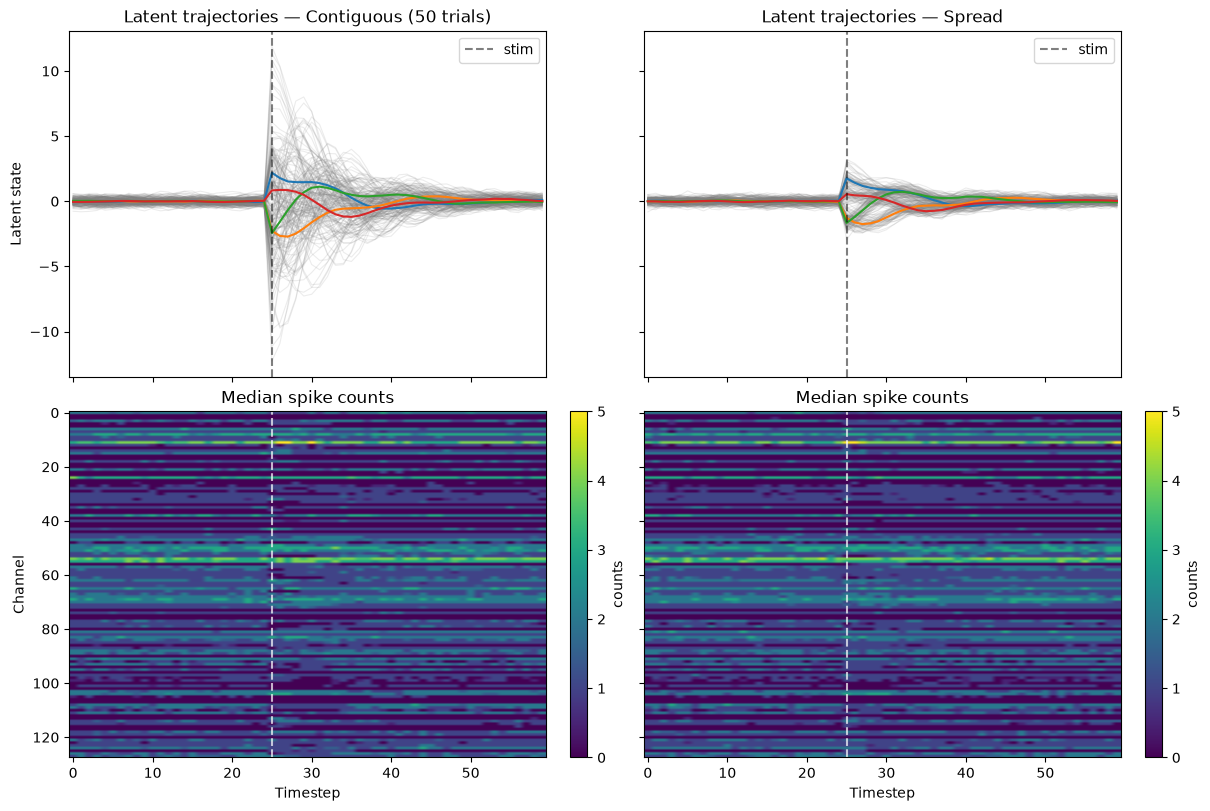

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True, sharex=True, sharey='row')

# --- Left column: contiguous ---
for i in range(n_trials):
    axes[0, 0].plot(X[i], color="grey", alpha=0.15, linewidth=0.8)
mean_X = X.mean(axis=0)
axes[0, 0].plot(mean_X)
axes[0, 0].axvline(t_stim, color="k", linestyle="--", alpha=0.5, label="stim")
axes[0, 0].set_title(f"Latent trajectories — Contiguous ({n_trials} trials)")
axes[0, 0].set_ylabel("Latent state")
axes[0, 0].legend()

median_Y = np.median(Y, axis=0)  # T x N
im1 = axes[1, 0].imshow(median_Y.T, aspect="auto", cmap="viridis")
axes[1, 0].axvline(t_stim, color="w", linestyle="--", alpha=0.7)
axes[1, 0].set_title("Median spike counts")
axes[1, 0].set_xlabel("Timestep")
axes[1, 0].set_ylabel("Channel")
fig.colorbar(im1, ax=axes[1, 0], label="counts")

# Right column: spread
for i in range(n_trials):
    axes[0, 1].plot(X_spread[i], color="grey", alpha=0.15, linewidth=0.8)
mean_X_spread = X_spread.mean(axis=0)
axes[0, 1].plot(mean_X_spread)
axes[0, 1].axvline(t_stim, color="k", linestyle="--", alpha=0.5, label="stim")
axes[0, 1].set_title(f"Latent trajectories — Spread")
axes[0, 1].legend()

median_Y_spread = np.median(Y_spread, axis=0)  # T x N
im2 = axes[1, 1].imshow(median_Y_spread.T, aspect="auto", cmap="viridis")
axes[1, 1].axvline(t_stim, color="w", linestyle="--", alpha=0.7)
axes[1, 1].set_title("Median spike counts")
axes[1, 1].set_xlabel("Timestep")
fig.colorbar(im2, ax=axes[1, 1], label="counts")

plt.show()

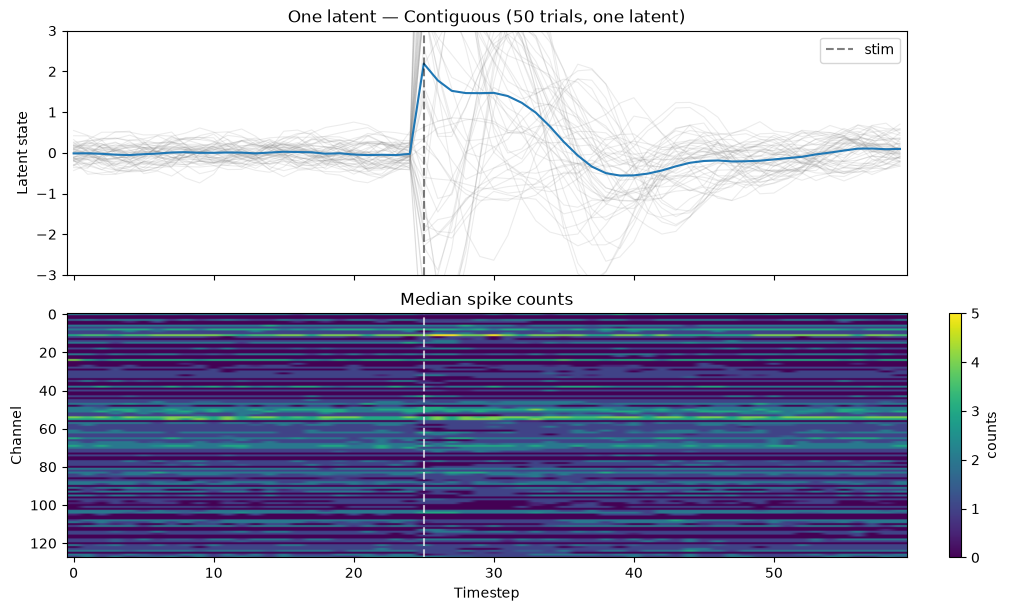

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True, sharex=True)

# Latent trajectories
for i in range(n_trials):
    axes[0].plot(X[i, :, 0], color="grey", alpha=0.15, linewidth=0.8)
mean_X = X.mean(axis=0)
axes[0].plot(mean_X[:, 0])
axes[0].axvline(t_stim, color="k", linestyle="--", alpha=0.5, label="stim")
axes[0].set_title(f"One latent — Contiguous ({n_trials} trials, one latent)")
axes[0].set_ylabel("Latent state")
axes[0].set_ylim(-3, 3)
axes[0].legend()

# Median spike counts
median_Y = np.median(Y, axis=0)  # T x N
im1 = axes[1].imshow(median_Y.T, aspect="auto", cmap="viridis")
axes[1].axvline(t_stim, color="w", linestyle="--", alpha=0.7)
axes[1].set_title("Median spike counts")
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel("Channel")
fig.colorbar(im1, ax=axes[1], label="counts")

plt.show()